# RetailMax CRM: exploratory data analysis

HCLTech Career Shaper, Project 27. This notebook is the EDA deliverable. It is executed, so every table and chart below is saved in the file, and each chart is also saved as a PNG in `docs/figures/` for the project report.

**What it covers**

1. Load the data and check shape, types, missing values, summary statistics.
2. What the raw file contained before cleaning.
3. RFM segments and churn: sizes, churn per segment, recency against frequency.
4. Order value, loyalty points and correlations.
5. The key finding: HCL's 500 rows carry no signal, the generated rows do.
6. Churn model results (logistic regression, random forest) and what drives churn.

**Where the data comes from.** `data/dataset_original.csv` is the 500-row file HCL supplied. `analysis/generate_dataset.py` adds 4,500 synthetic rows with realistic patterns (HCL's brief allows extra rows), injects labelled faults into a raw file, and `analysis/clean_dataset.py` produces `data/dataset.csv`. The rows are synthetic and anonymised: no names, phone numbers or emails exist anywhere in the project.

Colour code used in every chart: **orange means churned**; blue is the default series colour.

## 1. Setup and loading

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
warnings.filterwarnings("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "dataset.csv").exists())
sys.path.insert(0, str(ROOT / "analysis"))
from generate_dataset import rfm_scores, COLUMNS          # the shared RFM rule lives here
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# chart palette (validated categorical order: blue, orange, aqua). Orange always means "churned".
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10, "legend.frameon": False, "figure.dpi": 100,
})
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#e8f1fc", "#9ec5f4", "#256abf", "#0d366b"])
SEQ_ORANGE = LinearSegmentedColormap.from_list("seq_orange", ["#fdeee7", "#f6b79d", "#eb6834", "#8f2c0a"])
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ee", BLUE])
ORDER = ["Champion", "Loyal", "New", "At_Risk", "Lost"]
NUM = ["purchase_freq", "avg_order_value", "last_purchase_days", "loyalty_points"]

def legend_below(ax, ncol=2, fontsize=9.5):
    leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=ncol, markerscale=2.5, fontsize=fontsize)
    for h in leg.legend_handles:
        h.set_alpha(1)

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

raw = pd.read_csv(ROOT / "data" / "dataset_raw_combined.csv", dtype=str, keep_default_na=False)
df = pd.read_csv(ROOT / "data" / "dataset.csv")
orig = pd.read_csv(ROOT / "data" / "dataset_original.csv")
faults = pd.read_csv(ROOT / "data" / "anomaly_labels.csv")
assert list(df.columns) == COLUMNS
df["source"] = np.where(df["customer_id"] <= "C00500", "HCL original", "generated")
df["monetary"] = df["purchase_freq"] * df["avg_order_value"]
print(f"raw combined file : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"cleaned dataset   : {len(df):,} rows x {len(COLUMNS)} columns  ({(df.source == 'HCL original').sum()} HCL + {(df.source == 'generated').sum():,} generated)")

raw combined file : 5,020 rows x 9 columns
cleaned dataset   : 4,961 rows x 9 columns  (500 HCL + 4,461 generated)


### 1.1 Shape, types and missing values

In [2]:
cleaned = df[COLUMNS]
summary = pd.DataFrame({
    "dtype": cleaned.dtypes.astype(str),
    "missing (cleaned)": cleaned.isna().sum(),
    "missing (raw file)": (raw == "").sum(),
    "distinct": cleaned.nunique(),
})
display(summary)
print("duplicate customer_id in cleaned file:", int(cleaned.customer_id.duplicated().sum()))
print("duplicate customer_id in raw file    :", int(raw.customer_id.str.strip().duplicated().sum()))

,dtype,missing (cleaned),missing (raw file),distinct
customer_id,str,0,0,4961
age_group,str,0,8,5
region,str,0,8,5
purchase_freq,int64,0,0,48
avg_order_value,float64,0,10,4853
last_purchase_days,int64,0,5,364
loyalty_points,int64,0,8,2948
churn_flag,int64,0,6,2
rfm_segment,str,0,0,5


duplicate customer_id in cleaned file: 0
duplicate customer_id in raw file    : 20


### 1.2 Descriptive statistics

In [3]:
display(cleaned[NUM + ["churn_flag"]].describe().T.round(2))
for c in ["age_group", "region", "rfm_segment"]:
    print(f"\n{c}:", cleaned[c].value_counts().to_dict())
print(f"\nchurn rate: {cleaned.churn_flag.mean():.2%}")

,count,mean,std,min,25%,50%,75%,max
purchase_freq,4961.0,18.13,11.82,1.00,8.00,17.00,27.00,48.0
avg_order_value,4961.0,8636.49,4431.76,266.11,5276.02,7941.45,11149.01,19950.0
last_purchase_days,4961.0,115.18,107.95,1.00,20.00,70.00,200.00,365.0
loyalty_points,4961.0,2027.82,2106.05,16.00,447.00,1349.00,2833.00,9999.0
churn_flag,4961.0,0.15,0.36,0.00,0.00,0.00,0.00,1.0



age_group: {'26-35': 1469, '36-45': 1191, '18-25': 901, '46-55': 833, '55+': 567}

region: {'West': 1284, 'North': 1202, 'South': 1049, 'East': 827, 'Central': 599}

rfm_segment: {'At_Risk': 1445, 'Champion': 1016, 'Lost': 909, 'Loyal': 885, 'New': 706}

churn rate: 15.14%


## 2. Data quality: what the raw file contained

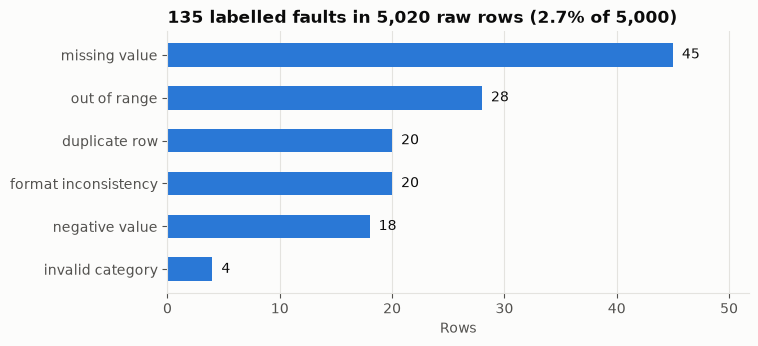

{'invalid category': 4, 'negative value': 18, 'format inconsistency': 20, 'duplicate row': 20, 'out of range': 28, 'missing value': 45}


In [4]:
fc = faults.assign(fault=faults.fault_type.str.replace("_", " ")).groupby("fault")["customer_id"].count().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(fc.index, fc.values, color=BLUE, height=0.55)
for i, v in enumerate(fc.values):
    ax.text(v + 0.8, i, str(v), va="center")
ax.set(xlim=(0, fc.max() * 1.15), xlabel="Rows", title=f"{len(faults)} labelled faults in {len(raw):,} raw rows ({faults.customer_id.nunique() / 5000:.1%} of 5,000)")
ax.grid(axis="y", visible=False)
save(fig, "fig00_injected_faults.png")
print(fc.to_dict())

**Reading the chart.** The raw file holds 135 labelled faults: 45 missing values, 28 out-of-range values, 20 duplicate rows, 20 format inconsistencies, 18 negative values and 4 invalid categories. That is 2.7% of 5,000 rows, inside the 2 to 5% HCL asks to label. Faults were injected only into generated rows; HCL's 500 rows are untouched.

**After cleaning:** 5,020 raw rows become 4,961. 20 duplicates are removed and 39 rows that cannot be repaired are dropped (a missing churn label, a missing recency or frequency, or a value outside the valid range). 0 nulls and 0 duplicate ids remain. Every rule and its count is in `data/cleaning_report.md`.

## 3. RFM segments and churn

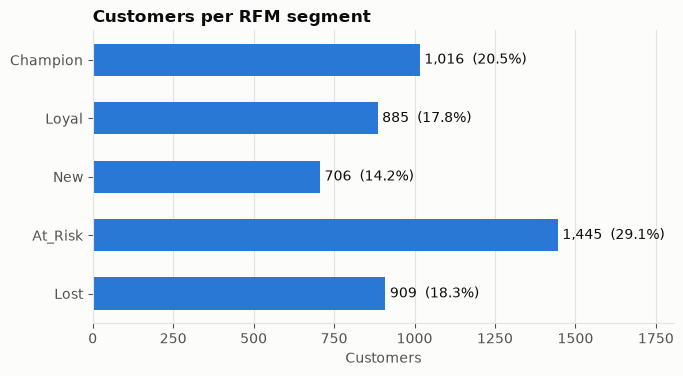

{'Champion': 1016, 'Loyal': 885, 'New': 706, 'At_Risk': 1445, 'Lost': 909}


In [5]:
cnt = df["rfm_segment"].value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(ORDER[::-1], cnt.values[::-1], color=BLUE, height=0.55)
for i, v in enumerate(cnt.values[::-1]):
    ax.text(v + cnt.max() * 0.01, i, f"{v:,}  ({v / len(df):.1%})", va="center")
ax.set(xlim=(0, cnt.max() * 1.25), xlabel="Customers", title="Customers per RFM segment")
ax.grid(axis="y", visible=False)
save(fig, "fig01_segment_distribution.png")
print(cnt.to_dict())

**Reading the chart.** At_Risk is the largest segment (1,445 customers, 29.1%), then Champion (1,016, 20.5%), Lost (909, 18.3%), Loyal (885, 17.8%) and New (706, 14.2%). No segment is below 14%, so each one has enough customers for a campaign test. At_Risk is biggest because two rule branches feed it: low recency score with F >= 3, and R = 3 with F <= 2.

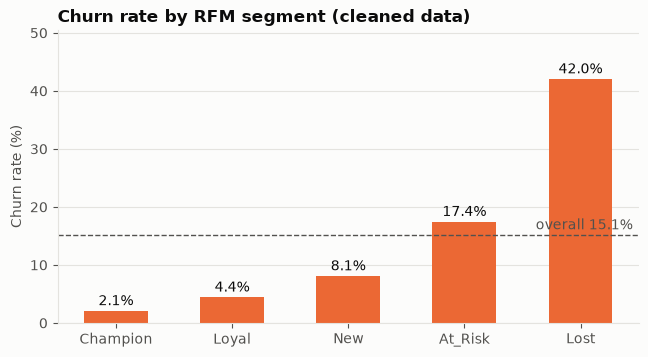

               mean  sum  count
rfm_segment                    
Champion     0.0207   21   1016
Loyal        0.0441   39    885
New          0.0807   57    706
At_Risk      0.1744  252   1445
Lost         0.4202  382    909


In [6]:
ch = df.groupby("rfm_segment")["churn_flag"].agg(["mean", "sum", "count"]).reindex(ORDER)
overall = df["churn_flag"].mean()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(ORDER, ch["mean"] * 100, color=ORANGE, width=0.55)
ax.axhline(overall * 100, color=MUTED, ls="--", lw=1)
ax.text(4.45, overall * 100 + 1.0, f"overall {overall:.1%}", ha="right", color=MUTED)
for i, m in enumerate(ch["mean"]):
    ax.text(i, m * 100 + 1.0, f"{m:.1%}", ha="center")
ax.set(ylabel="Churn rate (%)", title="Churn rate by RFM segment (cleaned data)", ylim=(0, ch["mean"].max() * 100 * 1.2))
ax.grid(axis="x", visible=False)
save(fig, "fig02_churn_by_segment.png")
print(ch.round(4).to_string())

**Reading the chart.** Churn rises step by step from Champion (2.1%) to Loyal (4.4%), New (8.1%), At_Risk (17.4%) and Lost (42.0%). The overall rate is 15.1%. Lost customers churn at 2.8 times the average, and they hold 382 of the 751 churners (50.9%). At_Risk and Lost together hold 84.4% of all churners, so a retention campaign aimed at those two segments reaches most of the people who leave.

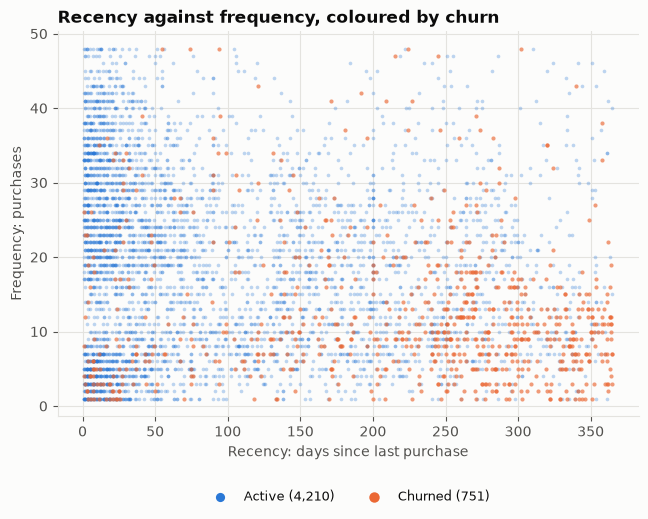

churn rate by recency band: {Interval(0, 90, closed='right'): 0.047, Interval(90, 180, closed='right'): 0.144, Interval(180, 270, closed='right'): 0.269, Interval(270, 365, closed='right'): 0.462}
churn rate by frequency band: {Interval(0, 10, closed='right'): 0.233, Interval(10, 20, closed='right'): 0.19, Interval(20, 30, closed='right'): 0.064, Interval(30, 48, closed='right'): 0.053}


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5))
kept, gone = df[df.churn_flag == 0], df[df.churn_flag == 1]
ax.scatter(kept.last_purchase_days, kept.purchase_freq, s=7, alpha=0.30, color=BLUE, linewidths=0, label=f"Active ({len(kept):,})")
ax.scatter(gone.last_purchase_days, gone.purchase_freq, s=9, alpha=0.65, color=ORANGE, linewidths=0, label=f"Churned ({len(gone):,})")
ax.set(xlabel="Recency: days since last purchase", ylabel="Frequency: purchases", title="Recency against frequency, coloured by churn")
legend_below(ax)
save(fig, "fig03_recency_vs_frequency.png")
bins = pd.cut(df.last_purchase_days, [0, 90, 180, 270, 365])
print("churn rate by recency band:", df.groupby(bins, observed=True).churn_flag.mean().round(3).to_dict())
fb = pd.cut(df.purchase_freq, [0, 10, 20, 30, 48])
print("churn rate by frequency band:", df.groupby(fb, observed=True).churn_flag.mean().round(3).to_dict())

**Reading the chart.** Churned customers (orange) gather in the bottom right: a long time since the last purchase and few purchases. Churn rate by recency band: up to 90 days 4.7%, 91 to 180 days 14.4%, 181 to 270 days 26.9%, 271 to 365 days 46.2%. By frequency: 1 to 10 purchases 23.3%, 11 to 20 purchases 19.0%, 21 to 30 purchases 6.4%, 31 to 48 purchases 5.3%. Recency is the stronger signal. The horizontal stripes appear because purchase_freq is a whole number.

## 4. Order value, loyalty and correlations

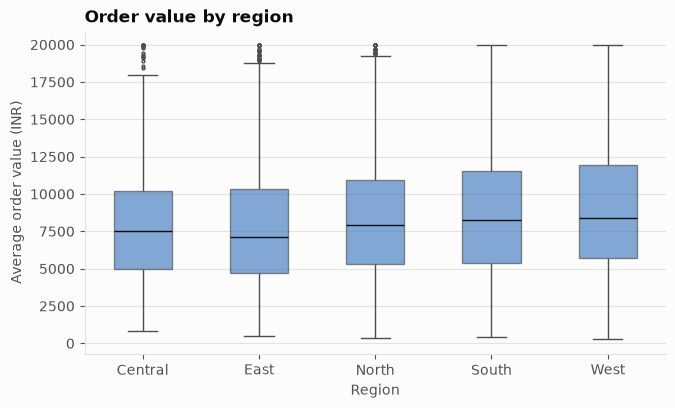

         median    mean     std
region                         
Central  7502.0  8012.0  4237.0
East     7105.0  8007.0  4358.0
North    7893.0  8476.0  4300.0
South    8230.0  8974.0  4521.0
West     8418.0  9208.0  4522.0


In [8]:
regions = sorted(df.region.unique())
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.boxplot(data=df, x="region", y="avg_order_value", order=regions, color=BLUE, width=0.5, fliersize=2,
            linewidth=1, boxprops={"alpha": 0.65}, medianprops={"color": INK}, ax=ax)
ax.set(xlabel="Region", ylabel="Average order value (INR)", title="Order value by region")
ax.grid(axis="x", visible=False)
save(fig, "fig04_aov_by_region.png")
print(df.groupby("region").avg_order_value.agg(["median", "mean", "std"]).round(0).to_string())

**Reading the chart.** Median order value runs from INR 7,105 in the East to INR 8,418 in the West, about 18% apart. West (mean 9,208) and South (8,974) sit highest, East (8,007) and Central (8,012) lowest. The spread is similar everywhere (standard deviation 4,237 to 4,522), so region moves the level, not the shape. The pattern is by design: the generator multiplies order value by a region factor between 0.88 and 1.08. It is a property of the generated data, not a finding about real customers.

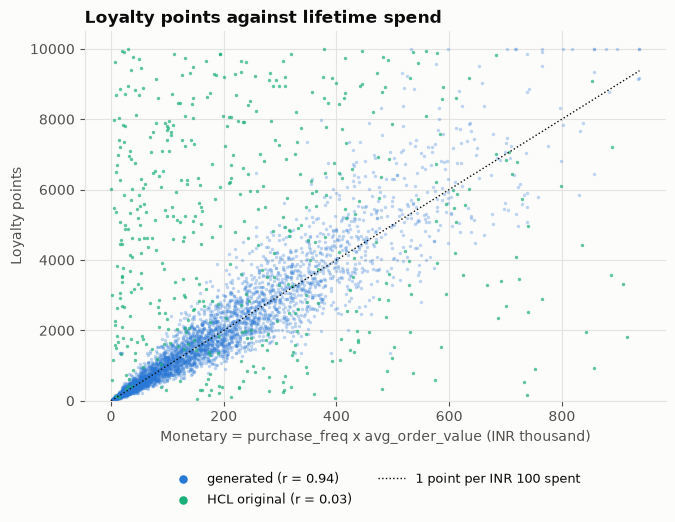

{'generated': np.float64(0.942), 'HCL original': np.float64(0.027)}


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
stats = {}
for src, col, a in [("generated", BLUE, 0.30), ("HCL original", AQUA, 0.70)]:
    d = df[df.source == src]
    stats[src] = np.corrcoef(d.monetary, d.loyalty_points)[0, 1]
    ax.scatter(d.monetary / 1000, d.loyalty_points, s=6, alpha=a, color=col, linewidths=0, label=f"{src} (r = {stats[src]:.2f})")
xs = np.linspace(0, df.monetary.max() / 1000, 50)
ax.plot(xs, xs * 10, color=INK, lw=1, ls=":", label="1 point per INR 100 spent")
ax.set(xlabel="Monetary = purchase_freq x avg_order_value (INR thousand)", ylabel="Loyalty points", ylim=(0, 10500),
       title="Loyalty points against lifetime spend")
legend_below(ax, ncol=2)
save(fig, "fig05_loyalty_vs_monetary.png")
print({k: round(v, 3) for k, v in stats.items()})

**Reading the chart.** In the generated rows loyalty points follow lifetime spend closely (correlation 0.94); the dotted line marks 1 point per INR 100 spent and the points scatter around it with about 25% noise. HCL's 500 rows (green) show a correlation of 0.03: a customer who spent INR 20,000 holds 9,000 points and one who spent INR 900,000 holds 500. Points with no link to spend are a second sign that HCL's rows are random. Across all 4,961 rows the correlation is 0.74 because the green rows dilute the pattern. Points are capped at 9,999, which flattens the top edge.

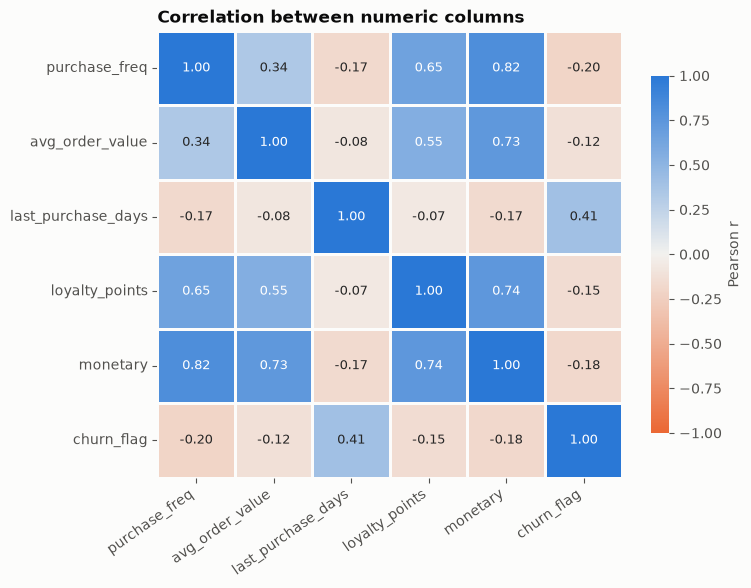

correlation with churn_flag: {'purchase_freq': -0.204, 'avg_order_value': -0.121, 'last_purchase_days': 0.405, 'loyalty_points': -0.155, 'monetary': -0.182}
correlation within generated rows only: {'purchase_freq': -0.24, 'avg_order_value': -0.146, 'last_purchase_days': 0.461, 'loyalty_points': -0.207, 'monetary': -0.22}
correlation within original rows only : {'purchase_freq': 0.023, 'avg_order_value': 0.019, 'last_purchase_days': 0.012, 'loyalty_points': -0.04, 'monetary': 0.046}


In [10]:
cols = NUM + ["monetary", "churn_flag"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 5.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.8, "label": "Pearson r"}, ax=ax, annot_kws={"size": 9})
ax.set(title="Correlation between numeric columns")
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save(fig, "fig06_correlation_heatmap.png")
print("correlation with churn_flag:", corr["churn_flag"].drop("churn_flag").round(3).to_dict())
print("correlation within generated rows only:", df[df.source == "generated"][cols].corr()["churn_flag"].drop("churn_flag").round(3).to_dict())
print("correlation within original rows only :", df[df.source == "HCL original"][cols].corr()["churn_flag"].drop("churn_flag").round(3).to_dict())

**Reading the chart.** Churn correlates +0.41 with recency and negatively with frequency (-0.20), monetary value (-0.18), loyalty points (-0.15) and order value (-0.12). Frequency, order value, loyalty points and monetary value are strongly linked to each other (0.34 to 0.82), because monetary is frequency times order value and points follow spend. That overlap matters for the model: a logistic regression splits credit among such columns, so a single coefficient should not be read as an independent effect.

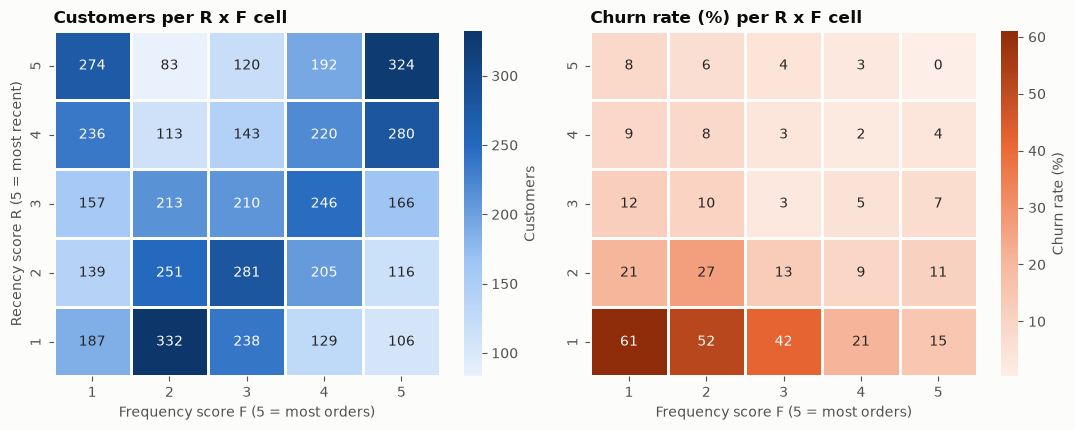

churn % by R score: {1: 43.2, 2: 16.5, 3: 7.1, 4: 5.0, 5: 3.8}
churn % by F score: {1: 20.6, 2: 27.7, 3: 15.3, 4: 6.9, 5: 5.1}


In [11]:
sc = rfm_scores(df)
t = df.join(sc)
grid_kw = dict(index="R", columns="F", aggfunc="count")
counts = t.pivot_table(values="customer_id", **grid_kw).reindex(index=[5, 4, 3, 2, 1], columns=[1, 2, 3, 4, 5])
churn = t.pivot_table(values="churn_flag", index="R", columns="F", aggfunc="mean").reindex(index=[5, 4, 3, 2, 1], columns=[1, 2, 3, 4, 5]) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(counts, annot=True, fmt=".0f", cmap=SEQ_BLUE, linewidths=2, linecolor=SURFACE, cbar_kws={"label": "Customers"}, ax=axes[0])
axes[0].set(title="Customers per R x F cell", xlabel="Frequency score F (5 = most orders)", ylabel="Recency score R (5 = most recent)")
sns.heatmap(churn, annot=True, fmt=".0f", cmap=SEQ_ORANGE, linewidths=2, linecolor=SURFACE, cbar_kws={"label": "Churn rate (%)"}, ax=axes[1])
axes[1].set(title="Churn rate (%) per R x F cell", xlabel="Frequency score F (5 = most orders)", ylabel="")
for a in axes:
    a.grid(False)
fig.tight_layout()
save(fig, "fig07_rfm_score_heatmap.png")
print("churn % by R score:", (t.groupby("R").churn_flag.mean() * 100).round(1).to_dict())
print("churn % by F score:", (t.groupby("F").churn_flag.mean() * 100).round(1).to_dict())

**Reading the chart.** Left: customers per R x F cell. An even spread would put about 198 in each cell; the corners are fuller (R5 F5 has 324, R1 F2 has 332) because recent customers also tend to buy often. Right: churn rate per cell. It falls with recency score: R = 1 churns 43.2%, R = 2 16.5%, R = 3 7.1%, R = 4 5.0%, R = 5 3.8%. The worst cell is R = 1, F = 1 at 61%; the best is R = 5, F = 5 at 0%. Within R = 1, more frequent buyers churn less (61% down to 15%), so frequency still helps once recency is fixed.

## 5. The key finding: HCL's 500 rows carry no signal

HCL original 500 rows, by the segment label HCL supplied:


,customers,churn_rate,mean_recency,mean_frequency
rfm_segment,,,,
Champion,117,0.137,185.436,23.846
Loyal,95,0.168,198.021,22.947
New,101,0.149,202.752,24.653
At_Risk,92,0.141,181.870,24.554
Lost,95,0.200,183.947,25.768


Generated rows, by the segment from the shared RFM rule:


,customers,churn_rate,mean_recency,mean_frequency
rfm_segment,,,,
Champion,988,0.015,16.810,31.513
Loyal,804,0.032,54.673,22.128
New,689,0.080,16.991,4.871
At_Risk,1160,0.183,176.274,16.667
Lost,820,0.444,243.254,7.494


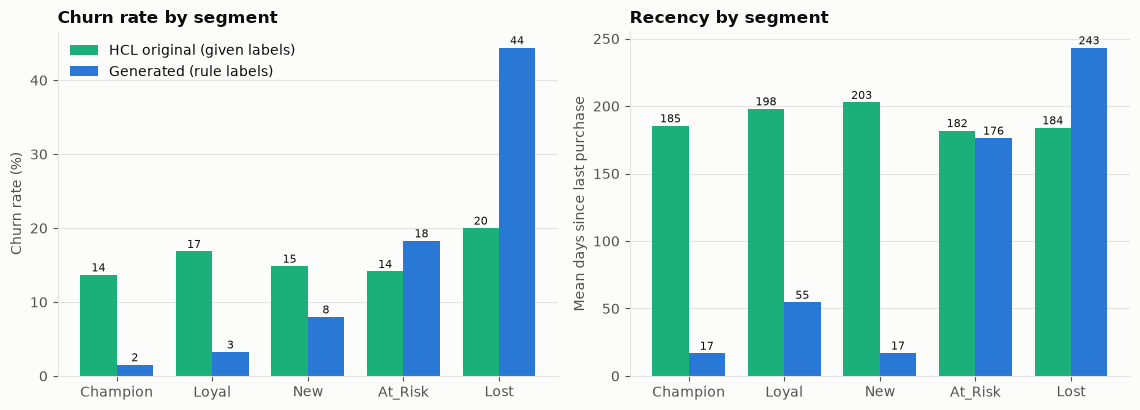

,churn rate,"corr(churn, recency)","corr(churn, frequency)","corr(points, monetary)",AUC of recency alone
rows,,,,,
HCL original (500),0.1580,0.012,0.023,0.027,0.509
"generated (4,461)",0.1506,0.461,-0.240,0.942,0.819


In [12]:
from sklearn.metrics import roc_auc_score
gen = df[df.source == "generated"]

def by_segment(d):
    return d.groupby("rfm_segment").agg(customers=("customer_id", "count"), churn_rate=("churn_flag", "mean"),
                                         mean_recency=("last_purchase_days", "mean"), mean_frequency=("purchase_freq", "mean")).reindex(ORDER)

t_o, t_g = by_segment(orig), by_segment(gen)
print("HCL original 500 rows, by the segment label HCL supplied:")
display(t_o.round(3))
print("Generated rows, by the segment from the shared RFM rule:")
display(t_g.round(3))

x = np.arange(len(ORDER)); w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, col, scale, ylabel, title in [
    (axes[0], "churn_rate", 100, "Churn rate (%)", "Churn rate by segment"),
    (axes[1], "mean_recency", 1, "Mean days since last purchase", "Recency by segment"),
]:
    b1 = ax.bar(x - w / 2, t_o[col] * scale, w, color=AQUA, label="HCL original (given labels)")
    b2 = ax.bar(x + w / 2, t_g[col] * scale, w, color=BLUE, label="Generated (rule labels)")
    for bars in (b1, b2):
        for r in bars:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height() + ax.get_ylim()[1] * 0.01, f"{r.get_height():.0f}", ha="center", fontsize=8)
    ax.set_xticks(x, ORDER)
    ax.set(ylabel=ylabel, title=title)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left")
fig.tight_layout()
save(fig, "fig08_original_vs_generated.png")

rows = []
for name, d in [("HCL original (500)", df[df.source == "HCL original"]), (f"generated ({len(gen):,})", gen)]:
    rows.append({
        "rows": name,
        "churn rate": round(d.churn_flag.mean(), 4),
        "corr(churn, recency)": round(d.churn_flag.corr(d.last_purchase_days), 3),
        "corr(churn, frequency)": round(d.churn_flag.corr(d.purchase_freq), 3),
        "corr(points, monetary)": round(d.loyalty_points.corr(d.monetary), 3),
        "AUC of recency alone": round(roc_auc_score(d.churn_flag, d.last_purchase_days), 3),
    })
display(pd.DataFrame(rows).set_index("rows"))

**Reading the chart. This is the key finding.** In HCL's 500 rows (green), churn is 13.7% to 20.0% in every segment and mean recency is 182 to 203 days in every segment. Champions (185 days) are no more recent than Lost customers (184 days). The 20.0% for Lost is about one standard deviation above the 15.8% overall rate (a 95-row group has a standard deviation of about 3.7 points), so it is within chance. In the generated rows (blue), churn runs from 1.5% (Champion) to 44.4% (Lost) and mean recency from 17 to 243 days.

The table gives the same picture in numbers: churn correlates 0.012 with recency in HCL's rows against 0.461 in the generated rows, and recency alone separates churners with an AUC of 0.509 (a coin flip is 0.5) against 0.819. The segment labels HCL supplied agree with the shared RFM rule on only 19.4% of rows, which is what random labels give (about 20%).

**What the project does about it.** A model cannot learn from labels that carry no signal. The generated rows follow the patterns real CRM data show (recent and frequent buyers stay; long-silent buyers leave), so the model and the segments can be shown working. The 500 HCL rows stay in the dataset (10% of rows, with random labels), and the report states plainly that results come from the generated patterns.

## 6. Churn model results

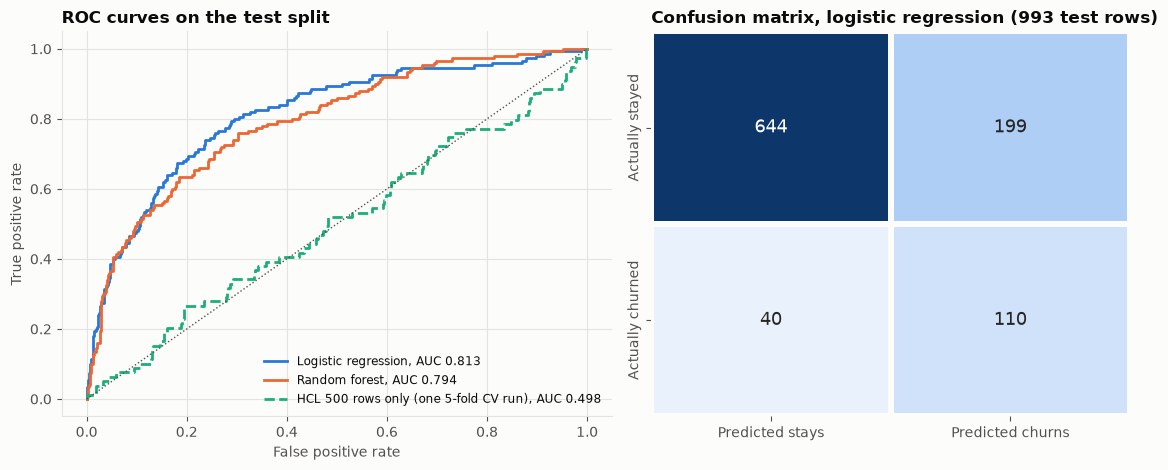

              model  accuracy  precision  recall     f1  roc_auc
Logistic Regression    0.7593     0.3560  0.7333 0.4793   0.8133
      Random Forest    0.8107     0.4069  0.5533 0.4689   0.7942
exported: {'accuracy': 0.7593, 'precision': 0.356, 'recall': 0.7333, 'f1': 0.4793, 'roc_auc': 0.8133, 'confusion_matrix': [[644, 199], [40, 110]], 'test_rows': 993} | original-500 AUC (CV): 0.4748


In [13]:
import json
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve
from train_churn_model import make_lr, make_rf, FEATURES, TARGET, SEED

model = json.loads((ROOT / "src" / "data" / "churn-model.json").read_text(encoding="utf-8"))
X_tr, X_te, y_tr, y_te = train_test_split(df[FEATURES], df[TARGET], test_size=0.2, stratify=df[TARGET], random_state=SEED)
lr, rf = make_lr().fit(X_tr, y_tr), make_rf().fit(X_tr, y_tr)
p_lr, p_rf = lr.predict_proba(X_te)[:, 1], rf.predict_proba(X_te)[:, 1]
o = df[df.source == "HCL original"]
p_o = cross_val_predict(make_lr(), o[FEATURES], o[TARGET], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for p, y, col, label, ls in [
    (p_lr, y_te, BLUE, "Logistic regression", "-"),
    (p_rf, y_te, ORANGE, "Random forest", "-"),
    (p_o, o[TARGET], AQUA, "HCL 500 rows only (one 5-fold CV run)", "--"),
]:
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=col, lw=2, ls=ls, label=f"{label}, AUC {roc_auc_score(y, p):.3f}")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves on the test split")
ax.legend(loc="lower right", fontsize=8.5)

cm = np.array(model["metrics"]["confusion_matrix"])
sns.heatmap(cm, annot=[[f"{v:,}" for v in r] for r in cm], fmt="", cmap=SEQ_BLUE, cbar=False, linewidths=3, linecolor=SURFACE,
            xticklabels=["Predicted stays", "Predicted churns"], yticklabels=["Actually stayed", "Actually churned"], ax=axes[1], annot_kws={"size": 13})
axes[1].set(title=f"Confusion matrix, logistic regression ({model['metrics']['test_rows']:,} test rows)")
axes[1].grid(False)
fig.tight_layout()
save(fig, "fig09_model_performance.png")
print(pd.DataFrame(model["comparison"]).to_string(index=False))
print("exported:", model["metrics"], "| original-500 AUC (CV):", model["original_500_roc_auc"])

**Reading the chart.** On 993 held-out rows the logistic regression reaches accuracy 0.759, precision 0.356, recall 0.733, F1 0.479 and ROC-AUC 0.813. The random forest reaches accuracy 0.811, precision 0.407, recall 0.553, F1 0.469 and ROC-AUC 0.794. The logistic regression ranks churners slightly better (higher AUC) and catches more of them: it finds 110 of the 150 churners (73.3%) but also flags 199 of 843 loyal customers, so only about 1 flag in 3 is a real churner. It is the exported model because it is exact in a browser (a sum and a sigmoid), explainable per customer, and ranks better here.

Accuracy alone misleads: predicting that nobody churns scores 0.849 on this test set. The green dashed curve is a model trained on HCL's 500 rows alone; it follows the diagonal (AUC 0.498 for this run, 0.475 averaged over 10 repeats of 5-fold cross-validation). It has nothing to learn.

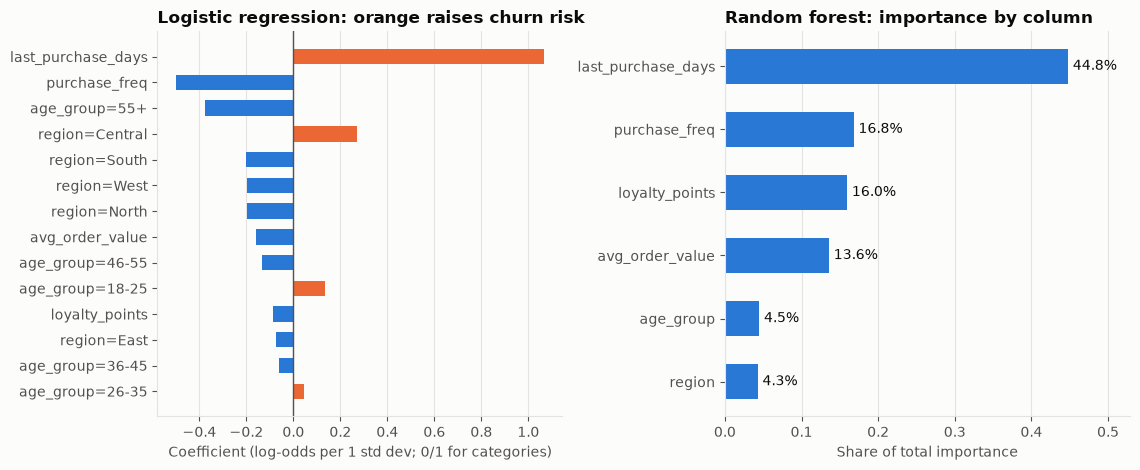

{'last_purchase_days': 1.067, 'purchase_freq': -0.5, 'age_group=55+': -0.378, 'region=Central': 0.273, 'region=South': -0.201, 'region=West': -0.196, 'region=North': -0.195, 'avg_order_value': -0.158, 'age_group=46-55': -0.135, 'age_group=18-25': 0.135, 'loyalty_points': -0.087, 'region=East': -0.076, 'age_group=36-45': -0.062, 'age_group=26-35': 0.044}
[{'feature': 'last_purchase_days', 'importance': 0.448}, {'feature': 'purchase_freq', 'importance': 0.1683}, {'feature': 'loyalty_points', 'importance': 0.1597}, {'feature': 'avg_order_value', 'importance': 0.136}, {'feature': 'age_group', 'importance': 0.045}, {'feature': 'region', 'importance': 0.043}]


In [14]:
coef = pd.Series(model["coef"]).sort_values(key=abs, ascending=True)
imp = pd.DataFrame(model["feature_importance"]).sort_values("importance")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
axes[0].barh(coef.index, coef.values, color=[ORANGE if v > 0 else BLUE for v in coef.values], height=0.6)
axes[0].axvline(0, color=MUTED, lw=1)
axes[0].set(xlabel="Coefficient (log-odds per 1 std dev; 0/1 for categories)", title="Logistic regression: orange raises churn risk")
axes[0].grid(axis="y", visible=False)
axes[1].barh(imp.feature, imp.importance, color=BLUE, height=0.55)
for i, v in enumerate(imp.importance):
    axes[1].text(v + 0.006, i, f"{v:.1%}", va="center")
axes[1].set(xlabel="Share of total importance", xlim=(0, imp.importance.max() * 1.18), title="Random forest: importance by column")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig10_feature_importance.png")
print(coef.sort_values(key=abs, ascending=False).round(3).to_dict())
print(imp.sort_values("importance", ascending=False).to_dict("records"))

**Reading the chart.** Recency dominates in both models. In the logistic regression it has the largest coefficient (+1.07 per standard deviation, about 108 days); in the random forest it holds 44.8% of the importance. Frequency comes next (coefficient -0.50, 16.8% importance). Customers aged 55+ carry lower risk (-0.38), customers in the Central region higher risk (+0.27), but age group and region together hold only 8.8% of the forest's importance.

Loyalty points get 16.0% importance in the forest but a small coefficient (-0.09) in the regression. Points follow spend and frequency, so the two models share the credit differently among overlapping columns. Both agree on the order that matters for a business reader: how long since the last purchase first, how often they buy second.

## 7. Summary

| Question | Answer |
|---|---|
| Final dataset | 4,961 rows, 9 columns, no nulls, unique ids, churn rate 15.14% |
| HCL's 500 rows | No signal: churn 13.7% to 20.0% and recency 182 to 203 days in every segment; given labels match the RFM rule on 19.4% of rows (chance level) |
| Generated rows | 4,461 rows with realistic patterns: churn from 1.5% (Champion) to 44.4% (Lost) |
| Who churns | Customers silent for a long time and with few purchases; At_Risk and Lost hold 84.4% of churners |
| Churn model | Logistic regression: accuracy 0.759, precision 0.356, recall 0.733, F1 0.479, ROC-AUC 0.813. Random forest: ROC-AUC 0.794 |
| Model on HCL's 500 alone | ROC-AUC 0.475 (10 x 5-fold CV), indistinguishable from 0.5 |

**Limits.** The patterns in 90% of the rows were designed by the generator, so the model scores show that the pipeline works end to end, not how well churn can be predicted at a real retailer. With real data the same scripts would retrain the model; the React app only needs the new `churn-model.json`. Precision is 35.6% at the 0.5 threshold, so a campaign built on the flag list would contact about two customers who were never going to leave for every one who was.